# Projet Machine Learning — Régression

## Prédire la progression du diabète à un an

Ce projet utilise le **jeu de données réel Diabetes de scikit-learn**.

Il contient **442 patients** et **10 variables mesurées au départ**. La cible est une mesure quantitative de la progression de la maladie un an plus tard.

### Objectifs

- explorer un vrai jeu de données ;
- préparer les variables pour un problème de régression ;
- séparer les données en entraînement et test ;
- entraîner une régression linéaire ;
- entraîner un Random Forest ;
- comparer les modèles avec MAE, RMSE et R² ;
- analyser les prédictions.

> Ce jeu de données est utilisé ici uniquement pour apprendre le machine learning. Il ne doit pas être utilisé pour prendre des décisions médicales.


## Variables

- `age` : âge
- `sex` : sexe
- `bmi` : indice de masse corporelle
- `bp` : pression artérielle moyenne
- `s1` à `s6` : six mesures sanguines
- `progression_maladie_1_an` : variable cible


## 1. Importer les bibliothèques

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 2. Charger les données

In [2]:
df = pd.read_csv("diabetes_regression.csv")

df.head()


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression_maladie_1_an
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


print(df.head(10))
print("\nDimensions :", df.shape)
print("\nTypes :")
print(df.dtypes)
print("\nValeurs manquantes :")
print(df.isna().sum())


In [3]:
# Votre code ici


## 3. Statistiques descriptives

In [4]:
df.describe()


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression_maladie_1_an
count,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000
mean,48.518100,1.468326,26.375792,94.647014,189.140271,115.439140,49.788462,4.070249,4.641411,91.260181,152.133484
std,13.109028,0.499561,4.418122,13.831283,34.608052,30.413081,12.934202,1.290450,0.522391,11.496335,77.093005
min,19.000000,1.000000,18.000000,62.000000,97.000000,41.600000,22.000000,2.000000,3.258100,58.000000,25.000000
25%,38.250000,1.000000,23.200000,84.000000,164.250000,96.050000,40.250000,3.000000,4.276700,83.250000,87.000000
50%,50.000000,1.000000,25.700000,93.000000,186.000000,113.000000,48.000000,4.000000,4.620050,91.000000,140.500000
75%,59.000000,2.000000,29.275000,105.000000,209.750000,134.500000,57.750000,5.000000,4.997200,98.000000,211.500000
max,79.000000,2.000000,42.200000,133.000000,301.000000,242.400000,99.000000,9.090000,6.107000,124.000000,346.000000


### Exercice 2

Observez les statistiques descriptives.

- Quelles variables ont les valeurs les plus grandes ?
- Quelle est la valeur moyenne de la cible ?
- Quelle est la valeur minimale et maximale de la cible ?


## 4. Distribution de la variable cible

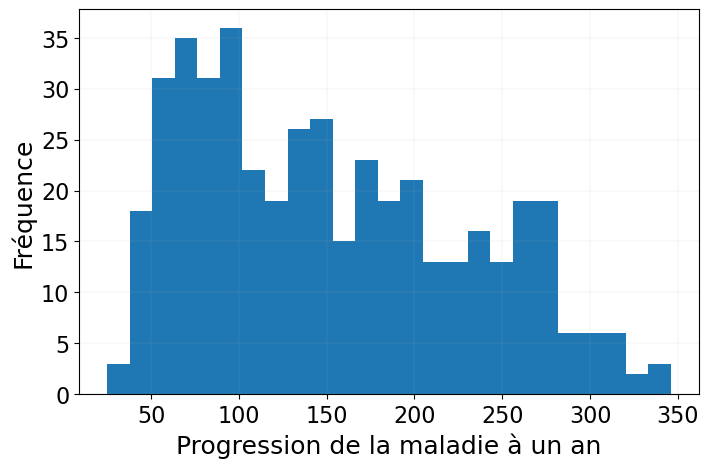

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(df["progression_maladie_1_an"], bins=25)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel("Progression de la maladie à un an", fontsize=18)
plt.ylabel("Fréquence", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.show()


## 5. Explorer les relations entre les variables

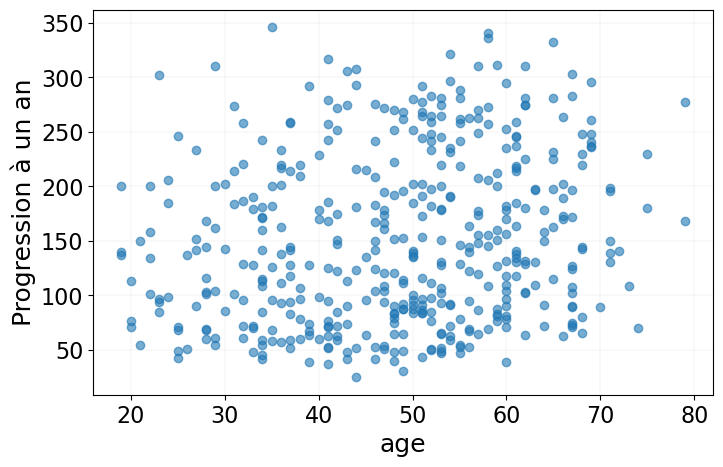

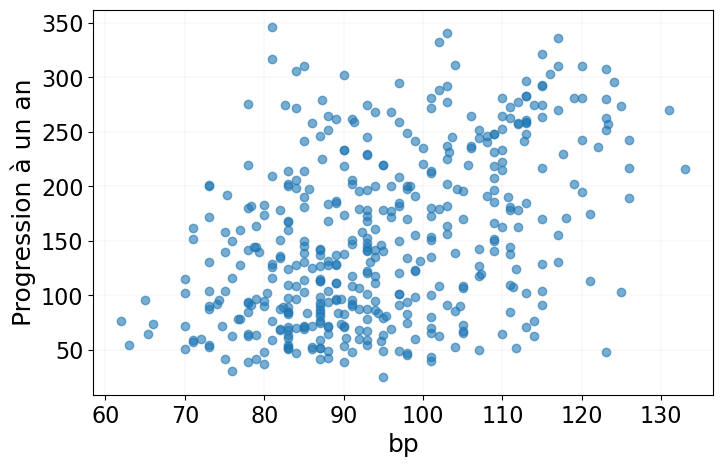

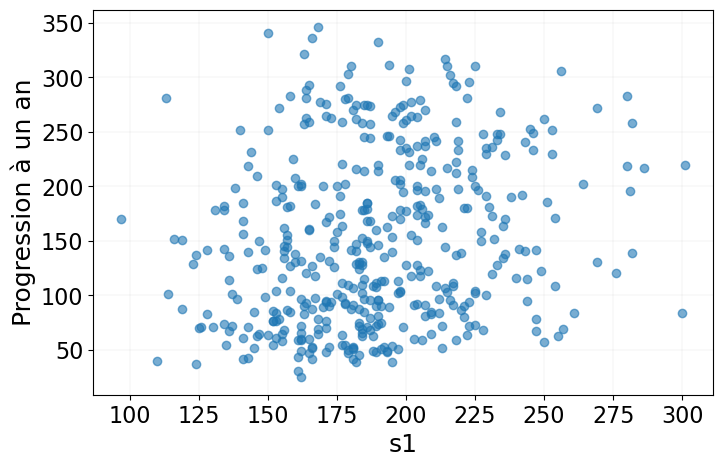

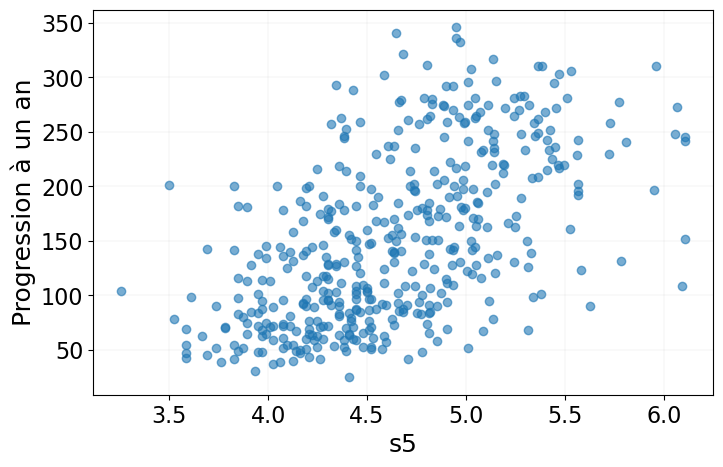

In [6]:
variables = ["age", "bp", "s1", "s5"]

for variable in variables:
    plt.figure(figsize=(8, 5))

    plt.scatter(
        df[variable],
        df["progression_maladie_1_an"],
        alpha=0.6
    )

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    plt.xlabel(variable, fontsize=18)
    plt.ylabel("Progression à un an", fontsize=18)
    plt.grid(True, linewidth=0.1)

    plt.show()


### Exercice 3

Créez des graphiques similaires pour :

- `age`
- `bp`
- `s1`
- `s5`

Quelles variables semblent avoir une relation avec la cible ?


In [7]:
# Votre code ici


## 6. Définir X et y

In [8]:
X = df.drop(columns="progression_maladie_1_an")
y = df["progression_maladie_1_an"]

print(X.shape)
print(y.shape)


(442, 10)
(442,)


## 7. Séparer les données

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)


Entraînement : (353, 10)
Test : (89, 10)


### Question

Pourquoi faut-il tester le modèle sur des données qu'il n'a pas utilisées pendant l'entraînement ?


## 8. Régression linéaire

In [10]:
model_linear = LinearRegression()

model_linear.fit(X_train, y_train)

pred_linear = model_linear.predict(X_test)


## 9. Évaluer le modèle

In [11]:
mae_linear = mean_absolute_error(y_test, pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, pred_linear))
r2_linear = r2_score(y_test, pred_linear)

print(f"MAE  : {mae_linear:.2f}")
print(f"RMSE : {rmse_linear:.2f}")
print(f"R²   : {r2_linear:.3f}")


MAE  : 42.79
RMSE : 53.85
R²   : 0.453


## 10. Valeurs observées contre valeurs prédites

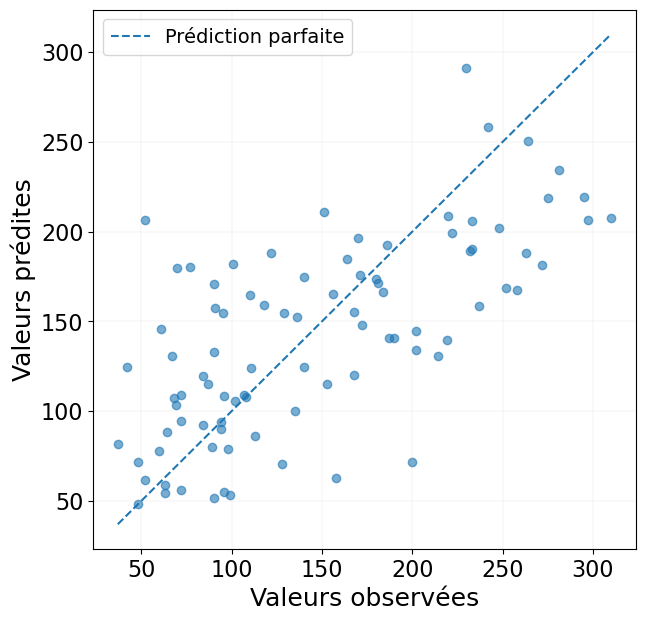

In [12]:
plt.figure(figsize=(7, 7))

plt.scatter(y_test, pred_linear, alpha=0.6)

minimum = min(y_test.min(), pred_linear.min())
maximum = max(y_test.max(), pred_linear.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Prédiction parfaite"
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Valeurs observées", fontsize=18)
plt.ylabel("Valeurs prédites", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.show()


### Exercice 4

- Que signifie un point situé exactement sur la diagonale ?
- Que signifie un point très éloigné de la diagonale ?


## 11. Random Forest

In [13]:
model_rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

model_rf.fit(X_train, y_train)

pred_rf = model_rf.predict(X_test)


## 12. Évaluer Random Forest

In [14]:
mae_rf = mean_absolute_error(y_test, pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
r2_rf = r2_score(y_test, pred_rf)

print(f"MAE  : {mae_rf:.2f}")
print(f"RMSE : {rmse_rf:.2f}")
print(f"R²   : {r2_rf:.3f}")


MAE  : 44.65
RMSE : 54.84
R²   : 0.432


## 13. Comparer les deux modèles

In [15]:
resultats = pd.DataFrame({
    "Modele": ["Régression linéaire", "Random Forest"],
    "MAE": [mae_linear, mae_rf],
    "RMSE": [rmse_linear, rmse_rf],
    "R2": [r2_linear, r2_rf]
})

resultats


,Modele,MAE,RMSE,R2
0,Régression linéaire,42.794095,53.853446,0.452603
1,Random Forest,44.649551,54.841781,0.432326


### Exercice 5

Quel modèle choisiriez-vous ?

Justifiez votre réponse à partir de :

- MAE
- RMSE
- R²


## 14. Importance des variables

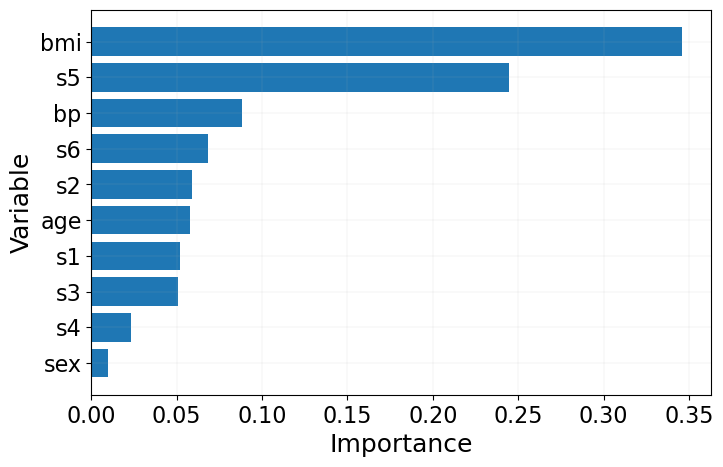

In [16]:
importance = pd.Series(
    model_rf.feature_importances_,
    index=X.columns
).sort_values()

plt.figure(figsize=(8, 5))

plt.barh(importance.index, importance.values)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel("Importance", fontsize=18)
plt.ylabel("Variable", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.show()


## 15. Défi

Essayez d'améliorer le modèle :

- changez `n_estimators` ;
- testez `max_depth` ;
- retirez certaines variables ;
- testez un autre modèle de régression.

Comparez toujours les nouvelles performances aux résultats précédents.
